# 5. Optimización por enjambre de partículas

La optimización por enjambre de partículas (*particle swarm optimization*, PSO) mueve un conjunto de soluciones, llamadas partículas, por el espacio de búsqueda. Cada partícula tiene una posición, que es la solución que representa, y una velocidad, que indica cuánto y en qué dirección se desplaza en la siguiente iteración. La velocidad combina la inercia del movimiento anterior con una atracción hacia la mejor posición que la partícula ha visitado y otra hacia la mejor posición que ha encontrado el enjambre completo.

El método se pensó para variables continuas, donde sumar una velocidad a una posición tiene un sentido directo. El hilo del capítulo es cómo se lleva esa idea a problemas combinatorios cambiando la representación de la solución. Los dos primeros ejemplos son continuos, la minimización de la función de Rosenbrock y la estimación de los coeficientes de una regresión lineal. Los dos siguientes son combinatorios. En el agente viajero, la velocidad se redefine como una lista de intercambios entre posiciones de una permutación. En el ruteo de vehículos, la regla de movimiento continua se conserva intacta y lo que cambia es la representación, con llaves aleatorias (*random keys*) que se decodifican en rutas. El capítulo 1 trata con más detalle la representación de soluciones.

## Minimización de la función de Rosenbrock

### El problema

La función de Rosenbrock,

$$f(x,y) = (1-x)^2 + 100\,(y-x^2)^2,$$

tiene su mínimo global en $(x,y) = (1,1)$, donde $f(1,1) = 0$. El mínimo está en el fondo de un valle angosto y curvo, de modo que acercarse a él exige cambiar de dirección a lo largo del valle. La búsqueda se hace en el rectángulo $[-2,2] \times [-1,3]$.

### Representación y regla de movimiento

Cada partícula $i$ guarda su posición $\mathbf{x}_i \in \mathbb{R}^2$, su velocidad $\mathbf{v}_i$, la mejor posición que ha visitado, $\mathbf{p}_i$, y el costo de esa posición. El enjambre guarda la mejor posición global, $\mathbf{g}$. En cada iteración, el método `optimizar` mueve cada partícula con la regla

$$\mathbf{v}_i \leftarrow w\,\mathbf{v}_i + c_1 r_1 (\mathbf{p}_i - \mathbf{x}_i) + c_2 r_2 (\mathbf{g} - \mathbf{x}_i),$$

$$\mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i,$$

donde $r_1$ y $r_2$ son números uniformes en $[0,1)$ que se sortean una vez por partícula e iteración y multiplican por igual a las dos coordenadas. El primer término es la inercia, con factor $w = 0{,}7$; el segundo es el componente cognitivo, con coeficiente $c_1 = 1{,}5$, y el tercero es el componente social, con coeficiente $c_2 = 1{,}5$. Después del movimiento, cada coordenada se trunca a los límites del rectángulo, $x \leftarrow \max\{\ell, \min\{u, x\}\}$; la velocidad, en cambio, no tiene tope.

Si el costo de la nueva posición mejora el de $\mathbf{p}_i$, la partícula actualiza su mejor posición y, si también mejora el de $\mathbf{g}$, el enjambre actualiza la suya en ese mismo momento. Por eso, las partículas que se mueven después dentro de la misma iteración ya usan el nuevo $\mathbf{g}$. Las posiciones iniciales se sortean de manera uniforme en el rectángulo y las velocidades iniciales, en $[-0{,}5;\,0{,}5]$ para cada coordenada.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits.mplot3d import Axes3D
import random
import time

In [2]:
# Definición de la función objetivo (función de Rosenbrock)
def funcion_objetivo(x, y):
    """
    Función de Rosenbrock: f(x,y) = (1-x)^2 + 100(y-x^2)^2
    Es una función no convexa utilizada como problema de prueba para algoritmos de optimización.
    Tiene un mínimo global en (x,y) = (1,1) donde f(1,1) = 0
    """
    return (1 - x)**2 + 100 * (y - x**2)**2

# Visualización de la función objetivo
def visualizar_funcion():
    """
    Crea una visualización 3D de la función objetivo para entender mejor
    el espacio de búsqueda.
    """
    fig = plt.figure(figsize=(10, 8))
    ax = fig.add_subplot(111, projection='3d')
    
    # Crear una malla de puntos
    x = np.linspace(-2, 2, 100)
    y = np.linspace(-1, 3, 100)
    X, Y = np.meshgrid(x, y)
    Z = funcion_objetivo(X, Y)
    
    # Graficar la superficie
    surf = ax.plot_surface(X, Y, Z, cmap=cm.coolwarm, alpha=0.8, linewidth=0)
    
    # Configurar etiquetas y título
    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('f(X,Y)')
    ax.set_title('Función de Rosenbrock')
    
    # Añadir una barra de color
    fig.colorbar(surf, shrink=0.5, aspect=5)
    
    return fig, ax

La clase `PSO` crea el enjambre en su constructor y lo mueve en el método `optimizar`. El método `visualizar_evolucion` dibuja la posición final de las partículas sobre la superficie y, en una segunda figura, la trayectoria de cada partícula sobre las curvas de nivel.

In [3]:
# Implementación del algoritmo PSO (Particle Swarm Optimization)
class PSO:
    """
    Implementación del algoritmo de Optimización por Enjambre de Partículas (PSO).
    
    Parámetros:
    - num_particulas: Número de partículas en el enjambre
    - max_iter: Número máximo de iteraciones
    - limites: Límites del espacio de búsqueda [min_x, max_x, min_y, max_y]
    - w: Factor de inercia
    - c1: Coeficiente cognitivo
    - c2: Coeficiente social
    """
    def __init__(self, num_particulas=30, max_iter=100, limites=[-2, 2, -1, 3], 
                 w=0.7, c1=1.5, c2=1.5):
        self.num_particulas = num_particulas
        self.max_iter = max_iter
        self.limites = limites
        self.w = w  # Factor de inercia
        self.c1 = c1  # Coeficiente cognitivo
        self.c2 = c2  # Coeficiente social
        
        # Inicializar partículas
        self.particulas = []
        self.mejor_global_pos = None
        self.mejor_global_costo = float('inf')
        self.historico_posiciones = []
        
        # Crear partículas iniciales
        for i in range(num_particulas):
            # Posición aleatoria dentro de los límites
            pos_x = random.uniform(limites[0], limites[1])
            pos_y = random.uniform(limites[2], limites[3])
            
            # Velocidad inicial aleatoria
            vel_x = random.uniform(-0.5, 0.5)
            vel_y = random.uniform(-0.5, 0.5)
            
            # Evaluar la posición
            costo = funcion_objetivo(pos_x, pos_y)
            
            # Guardar la partícula
            particula = {
                'posicion': np.array([pos_x, pos_y]),
                'velocidad': np.array([vel_x, vel_y]),
                'costo': costo,
                'mejor_pos': np.array([pos_x, pos_y]),
                'mejor_costo': costo
            }
            self.particulas.append(particula)
            
            # Actualizar el mejor global si es necesario
            if costo < self.mejor_global_costo:
                self.mejor_global_costo = costo
                self.mejor_global_pos = np.array([pos_x, pos_y])
    
    def optimizar(self, visualizar=True):
        """
        Ejecuta el algoritmo PSO para encontrar el mínimo de la función objetivo.
        
        Parámetros:
        - visualizar: Si es True, muestra la evolución del enjambre en cada iteración
        
        Retorna:
        - La mejor posición encontrada y su valor de función
        """
        if visualizar:
            fig, ax = visualizar_funcion()
            # Graficar el punto mínimo real
            ax.scatter(1, 1, 0, color='green', s=100, label='Mínimo real')
        
        # Guardar posiciones iniciales
        posiciones_iter = [np.array([p['posicion'] for p in self.particulas])]
        
        # Iterar hasta alcanzar el máximo de iteraciones
        for iter in range(self.max_iter):
            for i, particula in enumerate(self.particulas):
                # Actualizar velocidad
                r1, r2 = random.random(), random.random()
                
                componente_inercia = self.w * particula['velocidad']
                componente_cognitivo = self.c1 * r1 * (particula['mejor_pos'] - particula['posicion'])
                componente_social = self.c2 * r2 * (self.mejor_global_pos - particula['posicion'])
                
                nueva_velocidad = componente_inercia + componente_cognitivo + componente_social
                
                # Actualizar posición
                nueva_posicion = particula['posicion'] + nueva_velocidad
                
                # Aplicar límites
                nueva_posicion[0] = max(self.limites[0], min(self.limites[1], nueva_posicion[0]))
                nueva_posicion[1] = max(self.limites[2], min(self.limites[3], nueva_posicion[1]))
                
                # Evaluar nueva posición
                nuevo_costo = funcion_objetivo(nueva_posicion[0], nueva_posicion[1])
                
                # Actualizar partícula
                particula['posicion'] = nueva_posicion
                particula['velocidad'] = nueva_velocidad
                particula['costo'] = nuevo_costo
                
                # Actualizar mejor posición personal
                if nuevo_costo < particula['mejor_costo']:
                    particula['mejor_pos'] = nueva_posicion.copy()
                    particula['mejor_costo'] = nuevo_costo
                    
                    # Actualizar mejor global
                    if nuevo_costo < self.mejor_global_costo:
                        self.mejor_global_costo = nuevo_costo
                        self.mejor_global_pos = nueva_posicion.copy()
            
            # Guardar posiciones de esta iteración
            posiciones_iter.append(np.array([p['posicion'] for p in self.particulas]))
            
            # Mostrar progreso
            if (iter + 1) % 10 == 0 or iter == 0:
                print(f"Iteración {iter+1}/{self.max_iter}, Mejor costo: {self.mejor_global_costo:.6f}")
                print(f"Mejor posición: [{self.mejor_global_pos[0]:.6f}, {self.mejor_global_pos[1]:.6f}]")
        
        # Visualizar la evolución del enjambre
        if visualizar:
            self.visualizar_evolucion(posiciones_iter, fig, ax)
        
        return self.mejor_global_pos, self.mejor_global_costo
    
    def visualizar_evolucion(self, posiciones_iter, fig, ax):
        """
        Visualiza la evolución del enjambre a lo largo de las iteraciones.
        
        Parámetros:
        - posiciones_iter: Lista de arrays con las posiciones de las partículas en cada iteración
        - fig, ax: Figura y ejes de matplotlib para la visualización
        """
        # Graficar la posición final del enjambre
        pos_finales = posiciones_iter[-1]
        ax.scatter(pos_finales[:, 0], pos_finales[:, 1], 
                  funcion_objetivo(pos_finales[:, 0], pos_finales[:, 1]),
                  color='red', s=50, label='Partículas finales')
        
        # Graficar la mejor posición encontrada
        ax.scatter(self.mejor_global_pos[0], self.mejor_global_pos[1], 
                  self.mejor_global_costo, color='blue', s=100, 
                  label='Mejor solución')
        
        # Añadir leyenda
        ax.legend()
        
        # Crear una animación de la evolución
        plt.figure(figsize=(10, 8))
        
        # Graficar contorno de la función
        x = np.linspace(self.limites[0], self.limites[1], 100)
        y = np.linspace(self.limites[2], self.limites[3], 100)
        X, Y = np.meshgrid(x, y)
        Z = funcion_objetivo(X, Y)
        
        plt.contourf(X, Y, Z, 50, cmap='viridis', alpha=0.8)
        plt.colorbar(label='f(x,y)')
        
        # Graficar trayectoria de algunas partículas
        colores = plt.cm.jet(np.linspace(0, 1, self.num_particulas))
        
        for i in range(self.num_particulas):
            trayectoria = np.array([pos[i] for pos in posiciones_iter])
            plt.plot(trayectoria[:, 0], trayectoria[:, 1], '-', color=colores[i], alpha=0.5)
            plt.plot(trayectoria[-1, 0], trayectoria[-1, 1], 'o', color=colores[i])
        
        # Graficar el mínimo real y el encontrado
        plt.plot(1, 1, 'g*', markersize=15, label='Mínimo real')
        plt.plot(self.mejor_global_pos[0], self.mejor_global_pos[1], 'b*', 
                markersize=15, label='Mejor solución')
        
        plt.title('Trayectoria de las partículas durante la optimización')
        plt.xlabel('X')
        plt.ylabel('Y')
        plt.legend()
        plt.grid(True)
        
        plt.show()

### Ejecución

El enjambre tiene 30 partículas y hace 100 iteraciones. La salida informa el mejor costo cada 10 iteraciones.

Optimización por Enjambre de Partículas (PSO) para la función de Rosenbrock
Iteración 1/100, Mejor costo: 0.068131
Mejor posición: [0.770640, 0.581425]
Iteración 10/100, Mejor costo: 0.006505
Mejor posición: [0.927193, 0.856217]
Iteración 20/100, Mejor costo: 0.000344
Mejor posición: [1.013824, 1.029078]
Iteración 30/100, Mejor costo: 0.000018
Mejor posición: [0.996742, 0.993216]
Iteración 40/100, Mejor costo: 0.000000
Mejor posición: [1.000461, 1.000936]
Iteración 50/100, Mejor costo: 0.000000
Mejor posición: [1.000143, 1.000262]
Iteración 60/100, Mejor costo: 0.000000
Mejor posición: [1.000009, 1.000028]
Iteración 70/100, Mejor costo: 0.000000
Mejor posición: [0.999996, 0.999992]
Iteración 80/100, Mejor costo: 0.000000
Mejor posición: [0.999996, 0.999992]
Iteración 90/100, Mejor costo: 0.000000
Mejor posición: [1.000000, 0.999999]
Iteración 100/100, Mejor costo: 0.000000
Mejor posición: [1.000001, 1.000001]


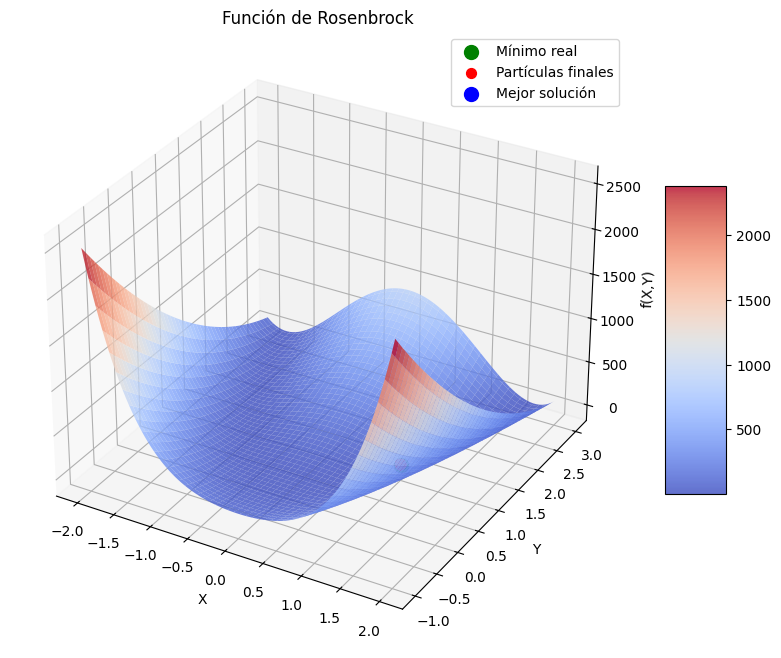

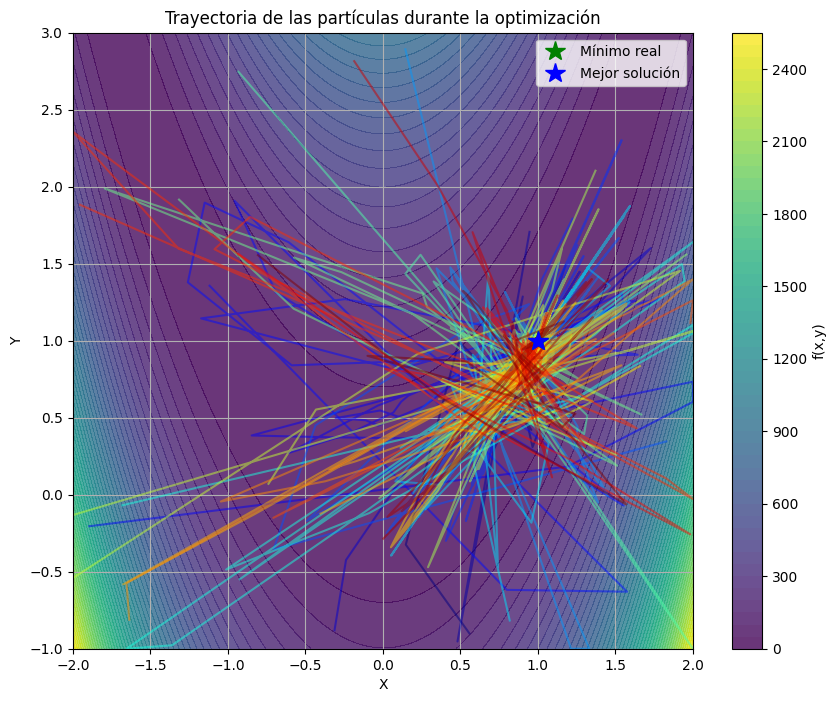


Resultados finales:
Mejor posición encontrada: [1.000001, 1.000001]
Valor de la función en el mínimo: 0.0000000000
Posición del mínimo real: [1.0, 1.0]
Valor de la función en el mínimo real: 0
Error absoluto: 0.0000011398
Tiempo de ejecución: 0.46 segundos


In [4]:
random.seed(42)
np.random.seed(42)

# Ejecutar el algoritmo
print("Optimización por Enjambre de Partículas (PSO) para la función de Rosenbrock")
print("=" * 80)

# Parámetros del algoritmo
num_particulas = 30
max_iter = 100
limites = [-2, 2, -1, 3]  # [min_x, max_x, min_y, max_y]

# Crear y ejecutar el optimizador
inicio = time.time()
pso = PSO(num_particulas=num_particulas, max_iter=max_iter, limites=limites)
mejor_pos, mejor_costo = pso.optimizar()
fin = time.time()

# Mostrar resultados
print("\nResultados finales:")
print(f"Mejor posición encontrada: [{mejor_pos[0]:.6f}, {mejor_pos[1]:.6f}]")
print(f"Valor de la función en el mínimo: {mejor_costo:.10f}")
print(f"Posición del mínimo real: [1.0, 1.0]")
print(f"Valor de la función en el mínimo real: {funcion_objetivo(1, 1)}")
print(f"Error absoluto: {np.sqrt((mejor_pos[0]-1)**2 + (mejor_pos[1]-1)**2):.10f}")
print(f"Tiempo de ejecución: {fin - inicio:.2f} segundos")

El mejor costo baja rápido en las primeras 30 iteraciones y, desde la iteración 40, la mejor posición coincide con $(1,1)$ en las tres primeras cifras decimales. En la figura de trayectorias, cada tramo es un salto recto entre dos posiciones consecutivas de una partícula. Los primeros saltos cruzan buena parte del rectángulo y los últimos se concentran alrededor del mínimo. PSO no usa la pendiente de la función, solo compara costos, de modo que las partículas no recorren el fondo del valle sino que saltan sobre él atraídas por $\mathbf{p}_i$ y $\mathbf{g}$.

## Estimación de los coeficientes de una regresión

### El problema

El segundo ejemplo usa PSO para ajustar una regresión lineal sobre los datos de vivienda de California que trae scikit-learn, con ocho variables explicativas de cada distrito y el valor mediano de la vivienda como respuesta. Los datos se dividen en 80 % para entrenamiento y 20 % para prueba, las variables se estandarizan y se agrega una columna de unos para el intercepto. El problema es encontrar el vector de coeficientes $\boldsymbol{\beta} \in \mathbb{R}^9$ que minimiza el error cuadrático medio (ECM) en el conjunto de entrenamiento,

$$\mathrm{ECM}(\boldsymbol{\beta}) = \frac{1}{n} \sum_{k=1}^{n} \left(y_k - \mathbf{x}_k^{\top} \boldsymbol{\beta}\right)^2 .$$

Este problema tiene solución cerrada, la de mínimos cuadrados ordinarios (*ordinary least squares*, OLS), y por eso sirve de control. PSO no usa el gradiente ni la estructura cuadrática del error; solo evalúa el ECM en las posiciones que visita.

### Representación y regla de movimiento

La posición de una partícula es el vector de coeficientes. Las posiciones iniciales se sortean de manera uniforme en $[-1, 1]$ y las velocidades iniciales en $[-0{,}1;\,0{,}1]$, para cada coordenada. La regla de movimiento es la misma del ejemplo anterior, salvo que ahora los números aleatorios se sortean por coordenada,

$$\mathbf{v}_i \leftarrow w\,\mathbf{v}_i + c_1\, \mathbf{r}_1 \odot (\mathbf{p}_i - \mathbf{x}_i) + c_2\, \mathbf{r}_2 \odot (\mathbf{g} - \mathbf{x}_i), \qquad \mathbf{x}_i \leftarrow \mathbf{x}_i + \mathbf{v}_i,$$

donde $\mathbf{r}_1$ y $\mathbf{r}_2$ son vectores de uniformes en $[0,1)$ y $\odot$ es el producto componente a componente. Las posiciones no tienen límites. El orden dentro de una iteración también cambia. En el método `ejecutar`, primero se mueven y se evalúan todas las partículas, actualizando $\mathbf{p}_i$ y $\mathbf{g}$, y después se recalculan todas las velocidades con el $\mathbf{g}$ de esa iteración. Por eso el primer movimiento usa la velocidad inicial sorteada.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

In [6]:
# Clase para la partícula del PSO
class Particula:
    def __init__(self, dim):
        # Inicializar posición y velocidad aleatoriamente
        self.posicion = np.random.uniform(-1, 1, dim)
        self.velocidad = np.random.uniform(-0.1, 0.1, dim)
        self.mejor_posicion = self.posicion.copy()
        self.fitness = float('inf')
        self.mejor_fitness = float('inf')
    
    def actualizar_velocidad(self, mejor_global, w, c1, c2):
        r1 = np.random.random(len(self.posicion))
        r2 = np.random.random(len(self.posicion))
        
        componente_inercia = w * self.velocidad
        componente_cognitivo = c1 * r1 * (self.mejor_posicion - self.posicion)
        componente_social = c2 * r2 * (mejor_global - self.posicion)
        
        self.velocidad = componente_inercia + componente_cognitivo + componente_social
    
    def actualizar_posicion(self):
        self.posicion = self.posicion + self.velocidad
        
    def evaluar_fitness(self, X, y):
        # Calcular el error cuadrático medio como función de fitness
        y_pred = X @ self.posicion
        mse = np.mean((y - y_pred) ** 2)
        self.fitness = mse
        
        # Actualizar mejor posición personal si mejora
        if self.fitness < self.mejor_fitness:
            self.mejor_fitness = self.fitness
            self.mejor_posicion = self.posicion.copy()
        
        return self.fitness

In [7]:
# Clase para el optimizador PSO para regresión lineal
class PSO_Regresion:
    def __init__(self, X, y, tam_poblacion=50, max_iter=100, w=0.7, c1=1.5, c2=1.5):
        self.X = X
        self.y = y
        self.dim = X.shape[1]  # Dimensión = número de características
        self.tam_poblacion = tam_poblacion
        self.max_iter = max_iter
        self.w = w  # Factor de inercia
        self.c1 = c1  # Factor cognitivo
        self.c2 = c2  # Factor social
        
        # Inicializar partículas
        self.particulas = [Particula(self.dim) for _ in range(tam_poblacion)]
        
        # Inicializar mejor global
        self.mejor_global_posicion = np.zeros(self.dim)
        self.mejor_global_fitness = float('inf')
        
        # Historial para análisis
        self.historial_fitness = []
    
    def ejecutar(self):
        # Evaluar fitness inicial de todas las partículas
        for p in self.particulas:
            fitness = p.evaluar_fitness(self.X, self.y)
            if fitness < self.mejor_global_fitness:
                self.mejor_global_fitness = fitness
                self.mejor_global_posicion = p.posicion.copy()
        
        # Iterar el algoritmo
        for i in range(self.max_iter):
            # Actualizar posiciones
            for p in self.particulas:
                p.actualizar_posicion()
                fitness = p.evaluar_fitness(self.X, self.y)
                
                # Actualizar mejor global si es necesario
                if fitness < self.mejor_global_fitness:
                    self.mejor_global_fitness = fitness
                    self.mejor_global_posicion = p.posicion.copy()
            
            # Actualizar velocidades
            for p in self.particulas:
                p.actualizar_velocidad(self.mejor_global_posicion, self.w, self.c1, self.c2)
            
            # Guardar historial
            self.historial_fitness.append(self.mejor_global_fitness)
            
            # Imprimir progreso
            if (i+1) % 10 == 0:
                print(f"Iteración {i+1}/{self.max_iter}, Mejor MSE: {self.mejor_global_fitness:.6f}")
    
    def predecir(self, X):
        return X @ self.mejor_global_posicion
    
    def mostrar_resultados(self):
        print("\nResultados finales:")
        print(f"Mejor MSE encontrado: {self.mejor_global_fitness:.6f}")
        print(f"Coeficientes: {self.mejor_global_posicion}")
        
        # Graficar convergencia
        plt.figure(figsize=(10, 6))
        plt.plot(range(len(self.historial_fitness)), self.historial_fitness, 'g-')
        plt.title('Convergencia del algoritmo PSO')
        plt.xlabel('Iteración')
        plt.ylabel('Error Cuadrático Medio (MSE)')
        plt.grid(True)
        plt.show()

### Datos y ejecución

El enjambre tiene 50 partículas y hace 100 iteraciones, con $w = 0{,}7$ y $c_1 = c_2 = 1{,}5$.

Cargando dataset de California Housing...
Dimensiones de los datos: X_train: (16512, 9), y_train: (16512,)

--- Solución con PSO ---
Iteración 10/100, Mejor MSE: 0.654827
Iteración 20/100, Mejor MSE: 0.562719
Iteración 30/100, Mejor MSE: 0.528058
Iteración 40/100, Mejor MSE: 0.524016
Iteración 50/100, Mejor MSE: 0.519562
Iteración 60/100, Mejor MSE: 0.518674
Iteración 70/100, Mejor MSE: 0.518286


Iteración 80/100, Mejor MSE: 0.518046
Iteración 90/100, Mejor MSE: 0.517959
Iteración 100/100, Mejor MSE: 0.517941

Resultados finales:
Mejor MSE encontrado: 0.517941
Coeficientes: [ 2.07258776e+00  8.52424611e-01  1.23122973e-01 -2.87673011e-01
  3.33573762e-01 -1.56142692e-03 -3.99305253e-02 -8.97173343e-01
 -8.69608335e-01]


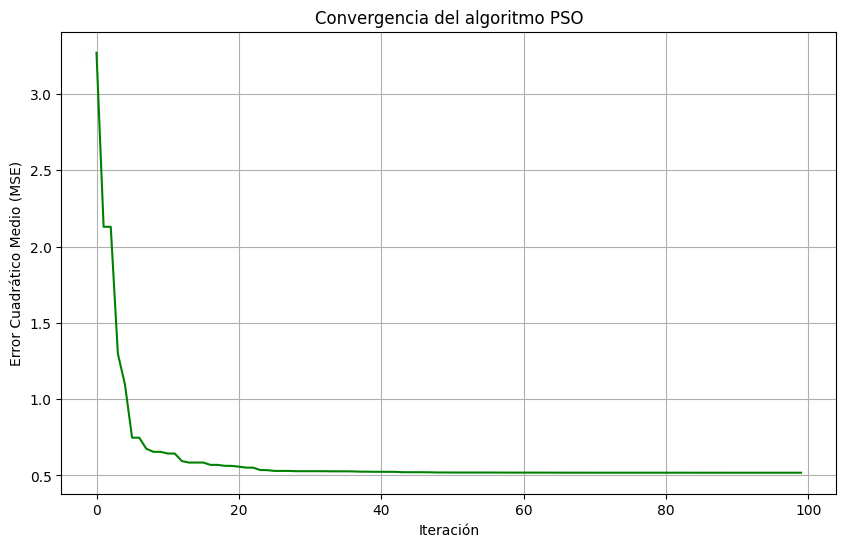

In [8]:
import warnings
# Algunas versiones de NumPy emiten advertencias espurias en el producto matricial
warnings.filterwarnings('ignore', message='.*encountered in matmul')

np.random.seed(42)

# Cargar el dataset de California Housing
print("Cargando dataset de California Housing...")
housing = fetch_california_housing()
X, y = housing.data, housing.target

# Dividir en conjuntos de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Escalar características
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Añadir término de sesgo (intercept)
X_train_scaled = np.column_stack((np.ones(X_train_scaled.shape[0]), X_train_scaled))
X_test_scaled = np.column_stack((np.ones(X_test_scaled.shape[0]), X_test_scaled))

print(f"Dimensiones de los datos: X_train: {X_train_scaled.shape}, y_train: {y_train.shape}")

# Solución con PSO
print("\n--- Solución con PSO ---")
pso = PSO_Regresion(
    X=X_train_scaled,
    y=y_train,
    tam_poblacion=50,
    max_iter=100,
    w=0.7,
    c1=1.5,
    c2=1.5
)

pso.ejecutar()
pso.mostrar_resultados()

Con los coeficientes que encontró el enjambre se evalúa el modelo en el conjunto de prueba y se compara con la solución de mínimos cuadrados.

In [9]:
# Evaluar en conjunto de prueba
y_pred_pso = pso.predecir(X_test_scaled)
mse_pso = mean_squared_error(y_test, y_pred_pso)
r2_pso = r2_score(y_test, y_pred_pso)

print(f"\nEvaluación en conjunto de prueba (PSO):")
print(f"MSE: {mse_pso:.6f}")
print(f"R²: {r2_pso:.6f}")

# Solución con OLS (Ordinary Least Squares)
print("\n--- Solución con OLS ---")
ols = LinearRegression(fit_intercept=False)  # False porque ya añadimos la columna de unos
ols.fit(X_train_scaled, y_train)

# Evaluar en conjunto de prueba
y_pred_ols = ols.predict(X_test_scaled)
mse_ols = mean_squared_error(y_test, y_pred_ols)
r2_ols = r2_score(y_test, y_pred_ols)

print(f"Coeficientes OLS: {ols.coef_}")
print(f"\nEvaluación en conjunto de prueba (OLS):")
print(f"MSE: {mse_ols:.6f}")
print(f"R²: {r2_ols:.6f}")

# Comparar resultados
print("\n--- Comparación de resultados ---")
print(f"MSE - PSO: {mse_pso:.6f}, OLS: {mse_ols:.6f}")
print(f"R² - PSO: {r2_pso:.6f}, OLS: {r2_ols:.6f}")


Evaluación en conjunto de prueba (PSO):
MSE: 0.555541
R²: 0.576055

--- Solución con OLS ---
Coeficientes OLS: [ 2.07194694  0.85438303  0.12254624 -0.29441013  0.33925949 -0.00230772
 -0.0408291  -0.89692888 -0.86984178]

Evaluación en conjunto de prueba (OLS):
MSE: 0.555892
R²: 0.575788

--- Comparación de resultados ---
MSE - PSO: 0.555541, OLS: 0.555892
R² - PSO: 0.576055, OLS: 0.575788


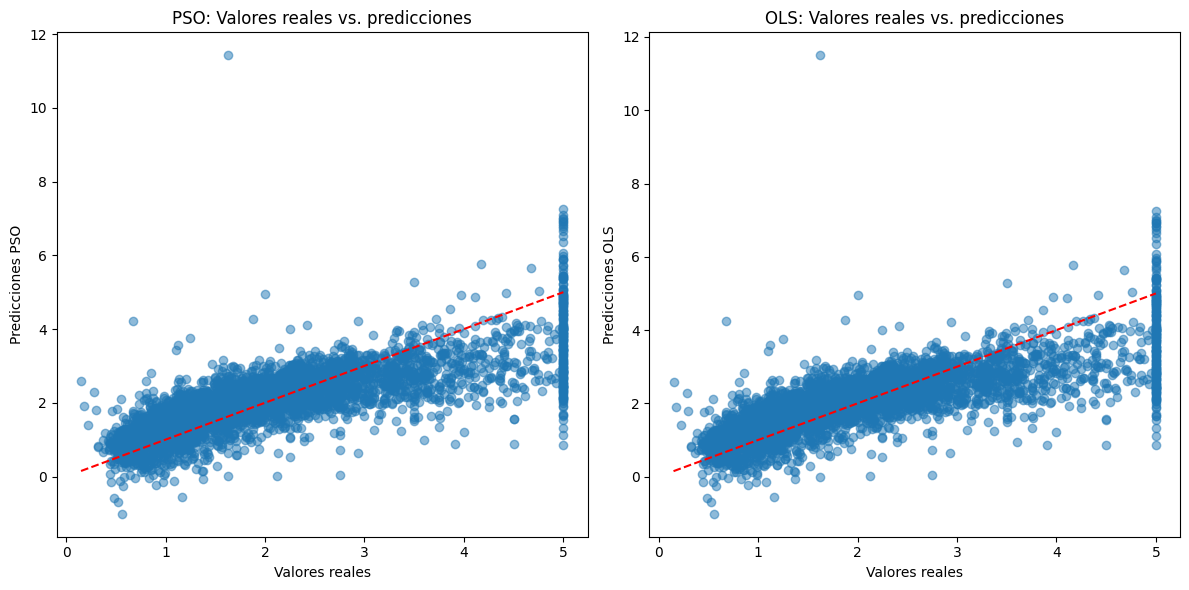

In [10]:
# Visualizar predicciones
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.scatter(y_test, y_pred_pso, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valores reales')
plt.ylabel('Predicciones PSO')
plt.title('PSO: Valores reales vs. predicciones')

plt.subplot(1, 2, 2)
plt.scatter(y_test, y_pred_ols, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel('Valores reales')
plt.ylabel('Predicciones OLS')
plt.title('OLS: Valores reales vs. predicciones')

plt.tight_layout()
plt.show()

El ECM de entrenamiento baja rápido durante las primeras 30 iteraciones y después mejora poco. Los coeficientes del enjambre coinciden con los de mínimos cuadrados en las dos primeras cifras decimales en ocho de las nueve componentes, y el ECM y el $R^2$ en el conjunto de prueba son prácticamente iguales con los dos métodos. Que el ECM de prueba de PSO resulte un poco menor no indica un mejor modelo. Mínimos cuadrados da el mínimo exacto del ECM de entrenamiento, así que el enjambre, en el mejor caso, lo iguala en entrenamiento; la diferencia en prueba aparece en la cuarta cifra decimal y se debe a que sus coeficientes no son exactamente los óptimos.

## El agente viajero: la velocidad como lista de intercambios

### El problema

En el problema del agente viajero (*traveling salesman problem*, TSP) se busca el recorrido cerrado más corto que visita una sola vez cada ciudad. El ejemplo tiene 20 ciudades con coordenadas enteras sorteadas entre 0 y 99, y la distancia entre dos ciudades es la euclidiana.

### Representación

La posición de una partícula es una permutación $\pi$ de las ciudades, y su aptitud es la longitud del recorrido,

$$L(\pi) = \sum_{k=1}^{n} d\left(\pi_k, \pi_{k+1}\right), \qquad \pi_{n+1} = \pi_1 .$$

Sumar un vector a una permutación no tiene sentido, así que el código redefine las tres operaciones que usa la regla de movimiento.

- La diferencia entre dos posiciones es una lista de intercambios. El método `calcular_swaps(ruta1, ruta2)` recorre las posiciones de izquierda a derecha y, cada vez que la ciudad de `ruta1` no coincide con la de `ruta2`, la intercambia con la posición donde está la ciudad que debería ir allí. Aplicados en ese orden, los intercambios $(i,j)$ resultantes convierten `ruta1` en `ruta2`. Llamemos $S(\mathbf{x} \to \mathbf{y})$ a esa lista.
- La velocidad es una lista de intercambios (*swaps*).
- Mover una partícula es aplicar, en orden, los intercambios de su velocidad a su permutación (método `aplicar_velocidad`).

### Regla de actualización de la velocidad

El método `actualizar_velocidad` arma la nueva velocidad concatenando tres sublistas,

$$\mathbf{v}_i \leftarrow V_w \,\Vert\, V_{c_1} \,\Vert\, V_{c_2},$$

que hacen el papel de los tres términos de la regla continua.

- Inercia. Con probabilidad $w$, y solo si la velocidad anterior no está vacía, $V_w$ es una muestra sin reemplazo de $\max\{1, \lfloor w\,|\mathbf{v}_i| \rfloor\}$ intercambios de la velocidad anterior; en otro caso, $V_w$ es vacía.
- Componente cognitivo. Con probabilidad $c_1$, $V_{c_1}$ es una muestra sin reemplazo de $\min\{\max\{1, \lfloor c_1\,|S| \rfloor\}, |S|\}$ intercambios de $S = S(\mathbf{x}_i \to \mathbf{p}_i)$.
- Componente social. Igual que el anterior, con $c_2$ y $S = S(\mathbf{x}_i \to \mathbf{g})$.

Los coeficientes cumplen así dos funciones, como probabilidad de incluir el componente y como fracción de los intercambios que se toman. Con $c_1 = c_2 = 1{,}5$, la prueba de probabilidad siempre se cumple y la muestra abarca todos los intercambios de la lista. Sin embargo, `random.sample` los devuelve en orden aleatorio y los intercambios no conmutan; además, la lista social se calcula desde $\mathbf{x}_i$ antes de aplicar la cognitiva. Por eso la partícula no llega exactamente a $\mathbf{p}_i$ ni a $\mathbf{g}$, sino a otra permutación construida con los mismos intercambios.

En cada iteración (método `iterar`), cada partícula aplica su velocidad, se evalúa y actualiza $\mathbf{p}_i$ y $\mathbf{g}$; al final se recalculan todas las velocidades. Como la velocidad inicial está vacía, en la primera iteración las partículas no se mueven. El factor de inercia es $w = 0{,}5$.

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import random
import math

In [12]:
# Definición de la clase Partícula
class Particula:
    def __init__(self, num_ciudades):
        # Inicialización de la posición (una permutación de ciudades)
        self.posicion = list(range(num_ciudades))
        random.shuffle(self.posicion)
        
        # Inicialización de la velocidad (lista de intercambios)
        self.velocidad = []
        
        # Mejor posición encontrada por esta partícula
        self.mejor_posicion = self.posicion.copy()
        
        # Valor de fitness (distancia total del recorrido)
        self.fitness = float('inf')
        self.mejor_fitness = float('inf')
    
    def calcular_fitness(self, matriz_distancias):
        """Calcula la distancia total del recorrido"""
        distancia_total = 0
        for i in range(len(self.posicion)):
            desde = self.posicion[i]
            hasta = self.posicion[(i + 1) % len(self.posicion)]
            distancia_total += matriz_distancias[desde][hasta]
        return distancia_total
    
    def actualizar_mejor_posicion(self):
        """Actualiza la mejor posición si la actual es mejor"""
        if self.fitness < self.mejor_fitness:
            self.mejor_fitness = self.fitness
            self.mejor_posicion = self.posicion.copy()
    
    def aplicar_velocidad(self):
        """Aplica los intercambios de la velocidad a la posición actual"""
        for intercambio in self.velocidad:
            i, j = intercambio
            self.posicion[i], self.posicion[j] = self.posicion[j], self.posicion[i]
    
    def actualizar_velocidad(self, mejor_global, w=0.5, c1=1.5, c2=1.5):
        """
        Actualiza la velocidad de la partícula
        
        Parámetros:
        - mejor_global: Mejor solución encontrada por el enjambre
        - w: Factor de inercia
        - c1: Factor cognitivo
        - c2: Factor social
        
        En PSO para TSP, la velocidad es una lista de operaciones de intercambio (swaps)
        """
        # Componente de inercia: mantener parte de la velocidad anterior
        nueva_velocidad = []
        if random.random() < w and self.velocidad:
            num_swaps = max(1, int(w * len(self.velocidad)))
            nueva_velocidad.extend(random.sample(self.velocidad, num_swaps))
        
        # Componente cognitivo: moverse hacia la mejor posición personal
        if random.random() < c1:
            # Calcular diferencias entre posición actual y mejor personal
            swaps_cognitivos = self.calcular_swaps(self.posicion, self.mejor_posicion)
            num_swaps = max(1, int(c1 * len(swaps_cognitivos)))
            if swaps_cognitivos:
                nueva_velocidad.extend(random.sample(swaps_cognitivos, min(num_swaps, len(swaps_cognitivos))))
        
        # Componente social: moverse hacia la mejor posición global
        if random.random() < c2:
            # Calcular diferencias entre posición actual y mejor global
            swaps_sociales = self.calcular_swaps(self.posicion, mejor_global)
            num_swaps = max(1, int(c2 * len(swaps_sociales)))
            if swaps_sociales:
                nueva_velocidad.extend(random.sample(swaps_sociales, min(num_swaps, len(swaps_sociales))))
        
        self.velocidad = nueva_velocidad
    
    def calcular_swaps(self, ruta1, ruta2):
        """
        Calcula los intercambios necesarios para transformar ruta1 en ruta2
        Implementación del algoritmo de ordenamiento por intercambios
        """
        swaps = []
        ruta_temp = ruta1.copy()
        
        for i in range(len(ruta1)):
            if ruta_temp[i] != ruta2[i]:
                j = ruta_temp.index(ruta2[i])
                ruta_temp[i], ruta_temp[j] = ruta_temp[j], ruta_temp[i]
                swaps.append((i, j))
        
        return swaps

In [13]:
# Clase principal del algoritmo PSO para TSP
class PSO_TSP:
    def __init__(self, ciudades, tam_poblacion=50, max_iter=100, w=0.5, c1=1.5, c2=1.5):
        """
        Inicializa el algoritmo PSO para TSP
        
        Parámetros:
        - ciudades: Lista de coordenadas (x, y) de las ciudades
        - tam_poblacion: Número de partículas en el enjambre
        - max_iter: Número máximo de iteraciones
        - w: Factor de inercia
        - c1: Factor cognitivo
        - c2: Factor social
        """
        self.ciudades = ciudades
        self.num_ciudades = len(ciudades)
        self.tam_poblacion = tam_poblacion
        self.max_iter = max_iter
        self.w = w
        self.c1 = c1
        self.c2 = c2
        
        # Calcular matriz de distancias entre ciudades
        self.matriz_distancias = self.calcular_matriz_distancias()
        
        # Inicializar población de partículas
        self.particulas = [Particula(self.num_ciudades) for _ in range(tam_poblacion)]
        
        # Evaluar fitness inicial de cada partícula
        for p in self.particulas:
            p.fitness = p.calcular_fitness(self.matriz_distancias)
            p.mejor_fitness = p.fitness
        
        # Inicializar mejor solución global
        self.mejor_global_posicion = min(self.particulas, key=lambda p: p.fitness).posicion.copy()
        self.mejor_global_fitness = min(self.particulas, key=lambda p: p.fitness).fitness
        
        # Para almacenar el historial de mejores soluciones
        self.historial_fitness = []
        self.historial_rutas = []
    
    def calcular_matriz_distancias(self):
        """Calcula la matriz de distancias euclidianas entre todas las ciudades"""
        matriz = np.zeros((self.num_ciudades, self.num_ciudades))
        for i in range(self.num_ciudades):
            for j in range(self.num_ciudades):
                if i != j:
                    x1, y1 = self.ciudades[i]
                    x2, y2 = self.ciudades[j]
                    matriz[i][j] = math.sqrt((x2 - x1)**2 + (y2 - y1)**2)
        return matriz
    
    def ejecutar(self):
        """Ejecuta el algoritmo PSO"""
        print("Iniciando PSO para TSP con {} ciudades y {} partículas...".format(
            self.num_ciudades, self.tam_poblacion))
        
        # Ejecución sin animación
        for i in range(self.max_iter):
            self.iterar()
            if (i + 1) % 10 == 0:
                print(f"Iteración {i+1}: Mejor distancia = {self.mejor_global_fitness:.2f}")
        
        # Mostrar resultado final
        self.mostrar_resultado()
    
    def iterar(self):
        """Realiza una iteración del algoritmo PSO"""
        for p in self.particulas:
            # Aplicar velocidad actual para obtener nueva posición
            p.aplicar_velocidad()
            
            # Evaluar nueva posición
            p.fitness = p.calcular_fitness(self.matriz_distancias)
            
            # Actualizar mejor posición personal
            p.actualizar_mejor_posicion()
            
            # Actualizar mejor posición global si es necesario
            if p.fitness < self.mejor_global_fitness:
                self.mejor_global_fitness = p.fitness
                self.mejor_global_posicion = p.posicion.copy()
        
        # Actualizar velocidades de todas las partículas
        for p in self.particulas:
            p.actualizar_velocidad(self.mejor_global_posicion, self.w, self.c1, self.c2)
        
        # Guardar historial para análisis
        self.historial_fitness.append(self.mejor_global_fitness)
        self.historial_rutas.append(self.mejor_global_posicion.copy())
    
    def mostrar_resultado(self):
        """Muestra el resultado final del algoritmo"""
        print("\nResultado final:")
        print(f"Mejor distancia encontrada: {self.mejor_global_fitness:.2f}")
        print(f"Mejor ruta: {self.mejor_global_posicion}")
        
        # Graficar la mejor ruta
        plt.figure(figsize=(10, 8))
        
        # Graficar ciudades
        x = [ciudad[0] for ciudad in self.ciudades]
        y = [ciudad[1] for ciudad in self.ciudades]
        plt.scatter(x, y, c='red', s=50)
        
        # Etiquetar ciudades
        for i, (x, y) in enumerate(self.ciudades):
            plt.annotate(str(i), (x, y), xytext=(5, 5), textcoords='offset points')
        
        # Graficar ruta
        ruta = self.mejor_global_posicion
        for i in range(self.num_ciudades):
            ciudad_actual = ruta[i]
            ciudad_siguiente = ruta[(i + 1) % self.num_ciudades]
            plt.plot([self.ciudades[ciudad_actual][0], self.ciudades[ciudad_siguiente][0]],
                     [self.ciudades[ciudad_actual][1], self.ciudades[ciudad_siguiente][1]], 'b-')
        
        plt.title(f'Mejor ruta encontrada (Distancia: {self.mejor_global_fitness:.2f})')
        plt.grid(True)
        plt.show()
        
        # Graficar convergencia
        plt.figure(figsize=(10, 6))
        plt.plot(range(len(self.historial_fitness)), self.historial_fitness, 'g-')
        plt.title('Convergencia del algoritmo PSO')
        plt.xlabel('Iteración')
        plt.ylabel('Distancia total')
        plt.grid(True)
        plt.show()

### Ejecución

El enjambre tiene 50 partículas y hace 100 iteraciones. Al terminar, el método `mostrar_resultado` dibuja el mejor recorrido y la curva de convergencia.

Iniciando PSO para TSP con 20 ciudades y 50 partículas...
Iteración 10: Mejor distancia = 677.59
Iteración 20: Mejor distancia = 616.20
Iteración 30: Mejor distancia = 582.71
Iteración 40: Mejor distancia = 577.12
Iteración 50: Mejor distancia = 529.76
Iteración 60: Mejor distancia = 529.76
Iteración 70: Mejor distancia = 529.76
Iteración 80: Mejor distancia = 529.76
Iteración 90: Mejor distancia = 529.76
Iteración 100: Mejor distancia = 529.76

Resultado final:
Mejor distancia encontrada: 529.76
Mejor ruta: [0, 17, 9, 6, 10, 18, 8, 1, 7, 12, 4, 19, 11, 13, 2, 14, 15, 3, 5, 16]


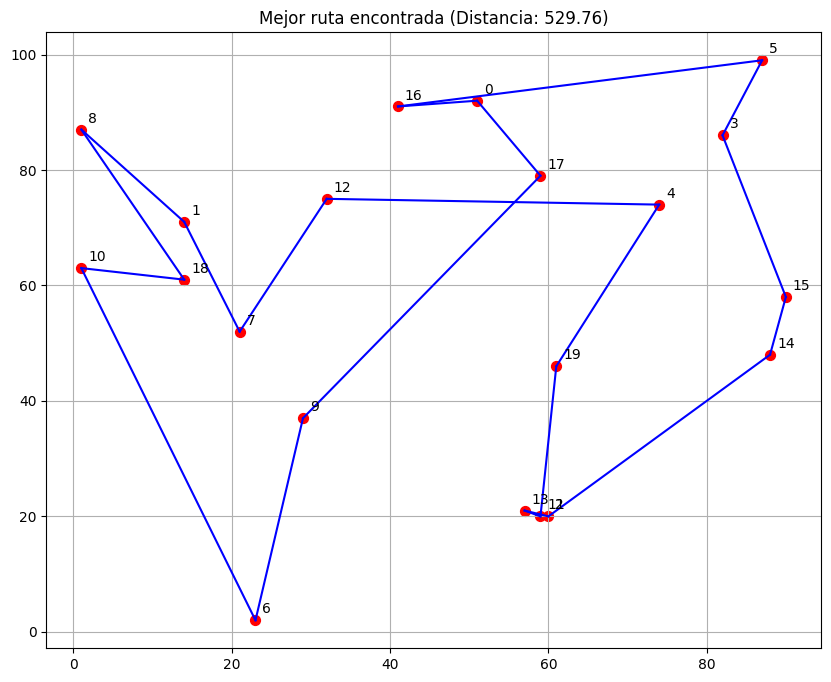

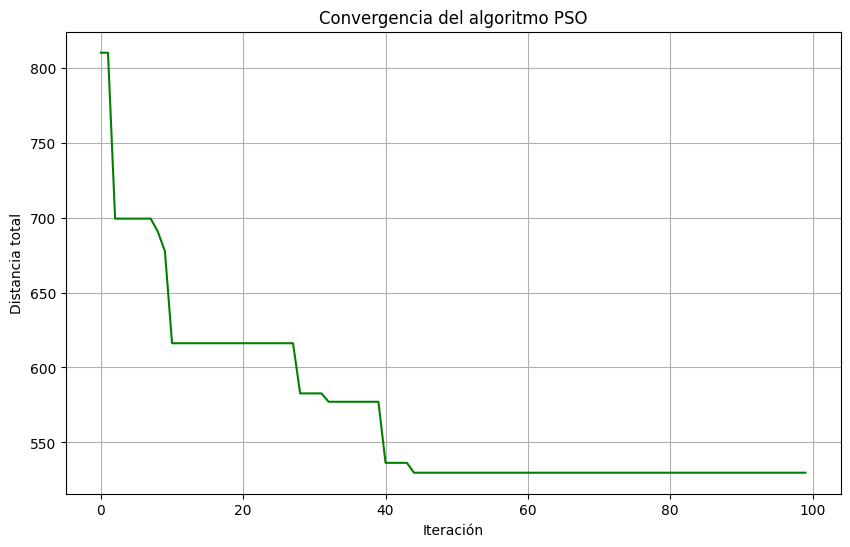

In [14]:
# Ejemplo de uso
# Generar ciudades aleatorias
random.seed(42)
np.random.seed(42)  # Para reproducibilidad
num_ciudades = 20
ciudades = [(np.random.randint(0, 100), np.random.randint(0, 100)) for _ in range(num_ciudades)]

# Configurar y ejecutar el algoritmo PSO
pso = PSO_TSP(
    ciudades=ciudades,
    tam_poblacion=50,
    max_iter=100,
    w=0.5,  # Factor de inercia
    c1=1.5,  # Factor cognitivo
    c2=1.5   # Factor social
)

# Ejecutar el algoritmo
pso.ejecutar()

El script original mostraba una animación del mejor recorrido iteración por iteración. En su lugar, la siguiente figura toma del historial `historial_rutas` el mejor recorrido después de algunas iteraciones.

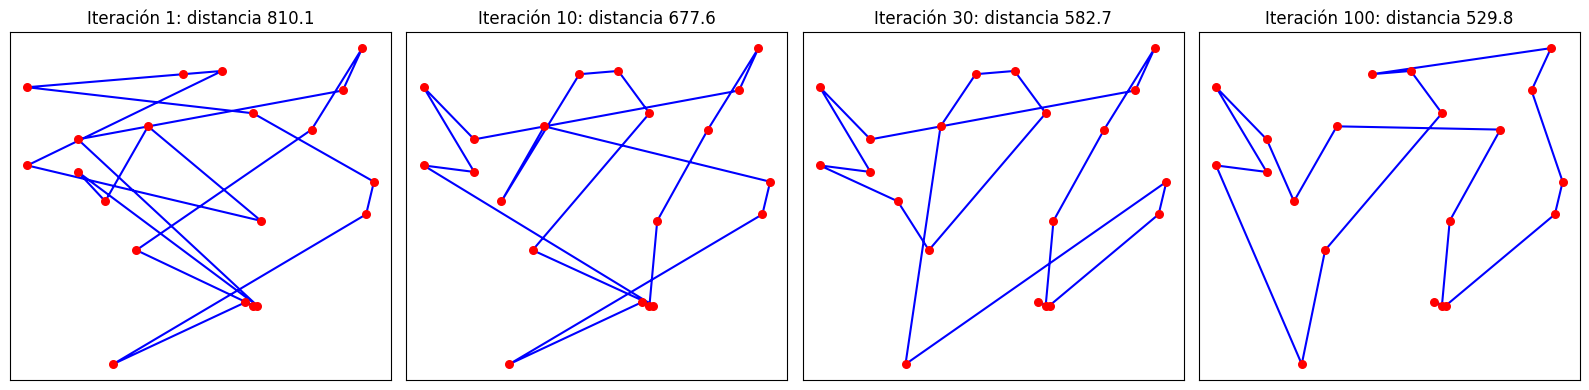

In [15]:
def graficar_rutas_tsp(pso, iteraciones):
    """Dibuja el mejor recorrido del enjambre después de las iteraciones indicadas"""
    fig, ejes = plt.subplots(1, len(iteraciones), figsize=(4 * len(iteraciones), 4))
    x = [ciudad[0] for ciudad in pso.ciudades]
    y = [ciudad[1] for ciudad in pso.ciudades]
    for ax, k in zip(ejes, iteraciones):
        ruta = pso.historial_rutas[k - 1]
        x_ruta = [pso.ciudades[c][0] for c in ruta] + [pso.ciudades[ruta[0]][0]]
        y_ruta = [pso.ciudades[c][1] for c in ruta] + [pso.ciudades[ruta[0]][1]]
        ax.plot(x_ruta, y_ruta, 'b-', lw=1.5)
        ax.scatter(x, y, c='red', s=30, zorder=3)
        ax.set_title(f'Iteración {k}: distancia {pso.historial_fitness[k - 1]:.1f}')
        ax.set_xticks([])
        ax.set_yticks([])
    plt.tight_layout()
    plt.show()

graficar_rutas_tsp(pso, [1, 10, 30, 100])

La distancia del mejor recorrido baja de forma escalonada durante las primeras 50 iteraciones y no cambia en las 50 restantes. El recorrido final todavía tiene cruces, como el del tramo de la ciudad 9 a la 17 con el de la 12 a la 4, y en un problema euclidiano un cruce siempre se puede deshacer para acortar el recorrido. Combinar un método poblacional con una búsqueda local que corrija defectos de este tipo es la idea de los algoritmos meméticos del capítulo 7.

## Ruteo de vehículos con llaves aleatorias

### El problema

En el problema de ruteo de vehículos (*vehicle routing problem*, VRP) del ejemplo hay un depósito en $(50, 50)$, 20 clientes con coordenadas enteras entre 0 y 99 y demandas enteras entre 1 y 9, y cinco vehículos con capacidad de 30 unidades cada uno. Cada vehículo sale del depósito, visita a sus clientes y regresa. Se busca la menor distancia total sin exceder la capacidad de ningún vehículo.

### Representación con llaves aleatorias

Aquí la regla de movimiento de PSO se conserva tal como en el caso continuo y el cambio está en la representación. La posición de una partícula es un vector de $n$ llaves en $[0,1]$, una por cliente, y el método `decodificar_rutas` lo convierte en rutas con estos pasos:

1. ordena los clientes de menor a mayor llave;
2. recorre los clientes en ese orden y asigna cada uno al vehículo de menor carga entre los que todavía tienen capacidad para su demanda (en caso de empate, al de menor índice); si ninguno tiene capacidad, lo asigna al vehículo de menor carga;
3. dentro de cada vehículo, los clientes se visitan en el orden en que se asignaron, es decir, de menor a mayor llave.

La llave decide el orden en que se procesan los clientes y el orden de visita dentro de cada ruta. El vehículo, en cambio, sale del balance de cargas y no de la llave misma. Si $Q_r$ es la carga de la ruta $r$ y $Q$ la capacidad, la aptitud que calcula `calcular_fitness` es la distancia total más una penalización por exceso de carga,

$$F = \sum_{r} \left[ d\left(0, c_{r,1}\right) + \sum_{k=1}^{|r|-1} d\left(c_{r,k}, c_{r,k+1}\right) + d\left(c_{r,|r|}, 0\right) \right] + 100 \sum_{r} \max\{0,\; Q_r - Q\},$$

donde $0$ es el depósito y $c_{r,k}$ es el $k$-ésimo cliente de la ruta $r$.

### Regla de movimiento

La regla es la del ejemplo de regresión, con números aleatorios por coordenada, y agrega dos truncamientos. Cada componente de la velocidad se limita a $[-0{,}1;\,0{,}1]$ y cada llave, a $[0,1]$. Las llaves iniciales son uniformes en $[0,1]$ y las velocidades iniciales, uniformes en $[-0{,}1;\,0{,}1]$. Un cambio en las llaves que no altere su orden deja la solución decodificada igual, de modo que muchas posiciones distintas representan las mismas rutas.

In [16]:
import numpy as np
import matplotlib.pyplot as plt
import random
import math
from collections import defaultdict

In [17]:
class Particula_VRP:
    """Representa una partícula en el algoritmo PSO para VRP con Random Keys"""
    
    def __init__(self, num_clientes, num_vehiculos):
        self.num_clientes = num_clientes
        self.num_vehiculos = num_vehiculos
        # Inicializar random keys: valores entre 0 y 1 para cada cliente
        self.posicion = np.random.random(num_clientes)
        # Inicializar velocidad aleatoria entre -0.1 y 0.1
        self.velocidad = np.random.uniform(-0.1, 0.1, num_clientes)
        # Mejor posición personal
        self.mejor_posicion = self.posicion.copy()
        # Fitness (costo de la ruta)
        self.fitness = float('inf')
        self.mejor_fitness = float('inf')
        # Rutas decodificadas
        self.rutas = []
    
    def actualizar_velocidad(self, mejor_global, w, c1, c2):
        """Actualiza la velocidad de la partícula"""
        r1 = np.random.random(self.num_clientes)
        r2 = np.random.random(self.num_clientes)
        
        # Componente de inercia
        inercia = w * self.velocidad
        
        # Componente cognitiva (atracción hacia la mejor posición personal)
        cognitiva = c1 * r1 * (self.mejor_posicion - self.posicion)
        
        # Componente social (atracción hacia la mejor posición global)
        social = c2 * r2 * (mejor_global - self.posicion)
        
        # Actualizar velocidad
        self.velocidad = inercia + cognitiva + social
        
        # Limitar velocidad
        self.velocidad = np.clip(self.velocidad, -0.1, 0.1)
    
    def actualizar_posicion(self):
        """Actualiza la posición de la partícula"""
        self.posicion += self.velocidad
        
        # Asegurar que los valores estén entre 0 y 1
        self.posicion = np.clip(self.posicion, 0, 1)
    
    def decodificar_rutas(self, clientes, deposito, capacidad_vehiculo):
        """Decodifica las random keys en rutas de vehículos"""
        # Crear pares (índice_cliente, random_key)
        pares = [(i, self.posicion[i]) for i in range(self.num_clientes)]
        
        # Ordenar clientes por su valor de random key
        pares_ordenados = sorted(pares, key=lambda x: x[1])
        
        # Inicializar rutas
        rutas = [[] for _ in range(self.num_vehiculos)]
        carga_actual = [0] * self.num_vehiculos
        
        # Asignar clientes a vehículos
        for cliente_idx, _ in pares_ordenados:
            # Calcular a qué vehículo asignar este cliente
            # Usamos el valor de random key para determinar el vehículo
            vehiculo_idx = 0
            min_carga = float('inf')
            
            # Asignar al vehículo con menor carga que pueda llevar la demanda
            for v in range(self.num_vehiculos):
                if (carga_actual[v] + clientes[cliente_idx][2] <= capacidad_vehiculo and 
                    carga_actual[v] < min_carga):
                    min_carga = carga_actual[v]
                    vehiculo_idx = v
            
            # Si no se puede asignar a ningún vehículo, crear uno nuevo si es posible
            if min_carga == float('inf'):
                # Buscar el vehículo con menor carga
                vehiculo_idx = carga_actual.index(min(carga_actual))
            
            # Asignar cliente al vehículo
            rutas[vehiculo_idx].append(cliente_idx)
            carga_actual[vehiculo_idx] += clientes[cliente_idx][2]
        
        self.rutas = rutas
        return rutas
    
    def calcular_fitness(self, clientes, deposito, capacidad_vehiculo):
        """Calcula el fitness (distancia total) de la partícula"""
        rutas = self.decodificar_rutas(clientes, deposito, capacidad_vehiculo)
        distancia_total = 0
        
        for ruta in rutas:
            if not ruta:  # Si la ruta está vacía
                continue
                
            # Distancia desde el depósito al primer cliente
            distancia_total += calcular_distancia(deposito, clientes[ruta[0]])
            
            # Distancia entre clientes consecutivos
            for i in range(len(ruta) - 1):
                distancia_total += calcular_distancia(clientes[ruta[i]], clientes[ruta[i + 1]])
            
            # Distancia desde el último cliente al depósito
            distancia_total += calcular_distancia(clientes[ruta[-1]], deposito)
        
        # Penalización por exceder la capacidad
        penalizacion = 0
        for i, ruta in enumerate(rutas):
            carga = sum(clientes[cliente_idx][2] for cliente_idx in ruta)
            if carga > capacidad_vehiculo:
                penalizacion += (carga - capacidad_vehiculo) * 100
        
        self.fitness = distancia_total + penalizacion
        
        # Actualizar mejor posición personal si es necesario
        if self.fitness < self.mejor_fitness:
            self.mejor_fitness = self.fitness
            self.mejor_posicion = self.posicion.copy()
        
        return self.fitness

In [18]:
def calcular_distancia(punto1, punto2):
    """Calcula la distancia euclidiana entre dos puntos"""
    return math.sqrt((punto1[0] - punto2[0])**2 + (punto1[1] - punto2[1])**2)

In [19]:
class PSO_VRP:
    """Implementación del algoritmo PSO para el problema VRP usando Random Keys"""
    
    def __init__(self, clientes, deposito, capacidad_vehiculo, num_vehiculos, 
                 tam_poblacion=50, max_iter=100, w=0.5, c1=1.5, c2=1.5):
        """
        Inicializa el algoritmo PSO para VRP
        
        Args:
            clientes: Lista de tuplas (x, y, demanda) para cada cliente
            deposito: Tupla (x, y) con la ubicación del depósito
            capacidad_vehiculo: Capacidad máxima de cada vehículo
            num_vehiculos: Número de vehículos disponibles
            tam_poblacion: Tamaño de la población de partículas
            max_iter: Número máximo de iteraciones
            w: Factor de inercia
            c1: Factor cognitivo
            c2: Factor social
        """
        self.clientes = clientes
        self.deposito = deposito
        self.capacidad_vehiculo = capacidad_vehiculo
        self.num_vehiculos = num_vehiculos
        self.num_clientes = len(clientes)
        self.tam_poblacion = tam_poblacion
        self.max_iter = max_iter
        self.w = w
        self.c1 = c1
        self.c2 = c2
        
        # Inicializar partículas
        self.particulas = [Particula_VRP(self.num_clientes, self.num_vehiculos) 
                          for _ in range(tam_poblacion)]
        
        # Evaluar fitness inicial
        for p in self.particulas:
            p.calcular_fitness(self.clientes, self.deposito, self.capacidad_vehiculo)
        
        # Inicializar mejor global
        self.mejor_global_fitness = float('inf')
        self.mejor_global_posicion = np.zeros(self.num_clientes)
        self.mejor_global_rutas = []
        
        # Para análisis y visualización
        self.historial_fitness = []
        self.historial_rutas = []
    
    def ejecutar(self):
        """Ejecuta el algoritmo PSO"""
        # Encontrar mejor global inicial
        for p in self.particulas:
            if p.fitness < self.mejor_global_fitness:
                self.mejor_global_fitness = p.fitness
                self.mejor_global_posicion = p.posicion.copy()
                self.mejor_global_rutas = p.rutas
        
        # Guardar estado inicial
        self.historial_fitness.append(self.mejor_global_fitness)
        self.historial_rutas.append(self.mejor_global_rutas)
        
        # Ejecutar sin animación
        for i in range(self.max_iter):
            self.iterar()
            if (i + 1) % 50 == 0:
                print(f"Iteración {i+1}/{self.max_iter}, Mejor fitness: {self.mejor_global_fitness:.2f}")
        
        # Mostrar resultado final
        self.mostrar_resultado()
    
    def iterar(self):
        """Realiza una iteración del algoritmo PSO"""
        # Actualizar posiciones
        for p in self.particulas:
            p.actualizar_posicion()
            p.calcular_fitness(self.clientes, self.deposito, self.capacidad_vehiculo)
        
        # Actualizar mejor global
        for p in self.particulas:
            if p.fitness < self.mejor_global_fitness:
                self.mejor_global_fitness = p.fitness
                self.mejor_global_posicion = p.posicion.copy()
                self.mejor_global_rutas = p.rutas
        
        # Actualizar velocidades
        for p in self.particulas:
            p.actualizar_velocidad(self.mejor_global_posicion, self.w, self.c1, self.c2)
        
        # Guardar historial
        self.historial_fitness.append(self.mejor_global_fitness)
        self.historial_rutas.append(self.mejor_global_rutas)
    
    def mostrar_resultado(self):
        """Muestra el resultado final del algoritmo"""
        print("\nResultado final:")
        print(f"Mejor distancia encontrada: {self.mejor_global_fitness:.2f}")
        
        # Mostrar rutas
        for i, ruta in enumerate(self.mejor_global_rutas):
            if ruta:  # Si la ruta no está vacía
                carga = sum(self.clientes[cliente_idx][2] for cliente_idx in ruta)
                print(f"Ruta {i+1}: {[r for r in ruta]} - Carga: {carga}/{self.capacidad_vehiculo}")
        
        # Graficar la mejor solución
        plt.figure(figsize=(10, 8))
        
        # Graficar depósito
        plt.scatter(self.deposito[0], self.deposito[1], c='red', s=100, marker='s')
        plt.annotate("Depósito", (self.deposito[0], self.deposito[1]), 
                    xytext=(5, 5), textcoords='offset points')
        
        # Graficar clientes
        for i, (x, y, demanda) in enumerate(self.clientes):
            plt.scatter(x, y, c='blue', s=50)
            plt.annotate(f"{i}({demanda})", (x, y), xytext=(5, 5), textcoords='offset points')
        
        # Graficar rutas
        colores = plt.cm.tab10(np.linspace(0, 1, self.num_vehiculos))
        
        for i, ruta in enumerate(self.mejor_global_rutas):
            if not ruta:  # Si la ruta está vacía
                continue
                
            color = colores[i % len(colores)]
            
            # Línea desde el depósito al primer cliente
            plt.plot([self.deposito[0], self.clientes[ruta[0]][0]],
                    [self.deposito[1], self.clientes[ruta[0]][1]], 
                    c=color, linestyle='-', linewidth=2, label=f"Vehículo {i+1}")
            
            # Líneas entre clientes
            for j in range(len(ruta) - 1):
                plt.plot([self.clientes[ruta[j]][0], self.clientes[ruta[j+1]][0]],
                        [self.clientes[ruta[j]][1], self.clientes[ruta[j+1]][1]],
                        c=color, linestyle='-', linewidth=2)
            
            # Línea desde el último cliente al depósito
            plt.plot([self.clientes[ruta[-1]][0], self.deposito[0]],
                    [self.clientes[ruta[-1]][1], self.deposito[1]],
                    c=color, linestyle='-', linewidth=2)
        
        plt.title(f'Mejor solución encontrada (Distancia: {self.mejor_global_fitness:.2f})')
        plt.legend()
        plt.grid(True)
        plt.show()
        
        # Graficar convergencia
        plt.figure(figsize=(10, 6))
        plt.plot(range(len(self.historial_fitness)), self.historial_fitness, 'g-')
        plt.title('Convergencia del algoritmo PSO para VRP')
        plt.xlabel('Iteración')
        plt.ylabel('Distancia total')
        plt.grid(True)
        plt.show()

### Ejecución

El enjambre tiene 50 partículas y hace 400 iteraciones, con $w = 0{,}5$ y $c_1 = c_2 = 1{,}5$.

Iteración 50/400, Mejor fitness: 939.01
Iteración 100/400, Mejor fitness: 928.35
Iteración 150/400, Mejor fitness: 928.35


Iteración 200/400, Mejor fitness: 928.35
Iteración 250/400, Mejor fitness: 928.35
Iteración 300/400, Mejor fitness: 928.35


Iteración 350/400, Mejor fitness: 928.35
Iteración 400/400, Mejor fitness: 928.35

Resultado final:
Mejor distancia encontrada: 928.35
Ruta 1: [5, 2, 8, 3] - Carga: 20/30
Ruta 2: [11, 10, 12] - Carga: 23/30
Ruta 3: [9, 7, 15] - Carga: 22/30
Ruta 4: [13, 18, 16, 4, 14, 6, 19] - Carga: 23/30
Ruta 5: [1, 0, 17] - Carga: 19/30


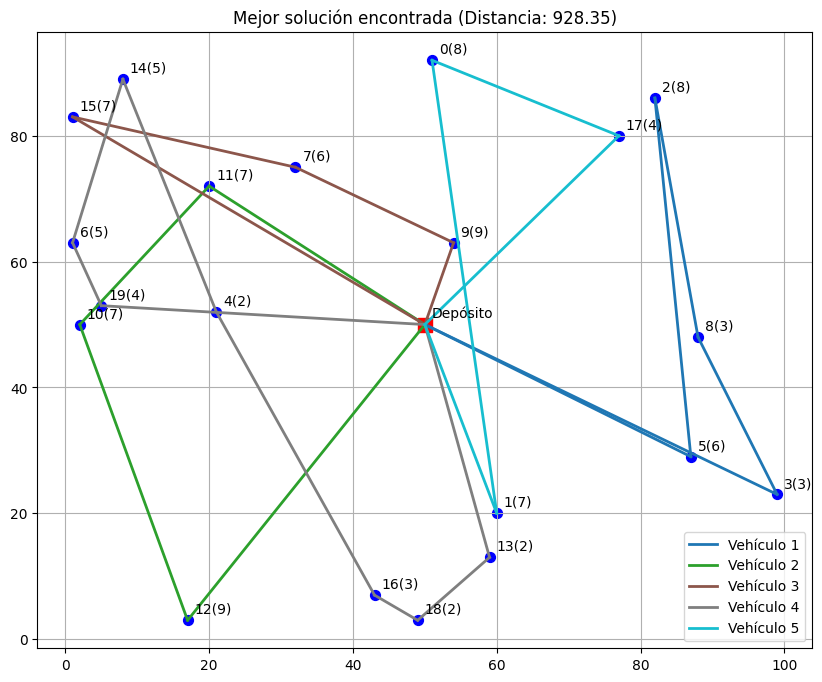

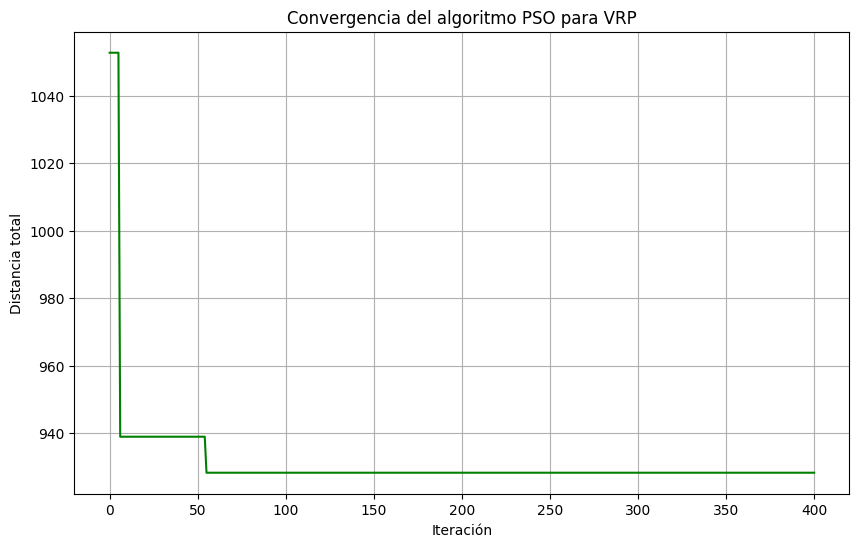

In [20]:
# Ejemplo de uso
# Configuración del problema
random.seed(42)
np.random.seed(42)  # Para reproducibilidad

# Depósito en el centro
deposito = (50, 50)

# Generar clientes aleatorios con demandas
num_clientes = 20
clientes = []
for _ in range(num_clientes):
    x = np.random.randint(0, 100)
    y = np.random.randint(0, 100)
    demanda = np.random.randint(1, 10)
    clientes.append((x, y, demanda))

# Configuración del VRP
capacidad_vehiculo = 30
num_vehiculos = 5

# Configurar y ejecutar el algoritmo PSO
pso = PSO_VRP(
    clientes=clientes,
    deposito=deposito,
    capacidad_vehiculo=capacidad_vehiculo,
    num_vehiculos=num_vehiculos,
    tam_poblacion=50,
    max_iter=400,
    w=0.5,  # Factor de inercia
    c1=1.5,  # Factor cognitivo
    c2=1.5   # Factor social
)

# Ejecutar el algoritmo
pso.ejecutar()

Como en el agente viajero, la animación del script original se sustituye por las mejores rutas del enjambre en algunos momentos de la búsqueda. En `historial_rutas`, la posición 0 guarda el estado inicial y la posición $k$, el estado después de la iteración $k$.

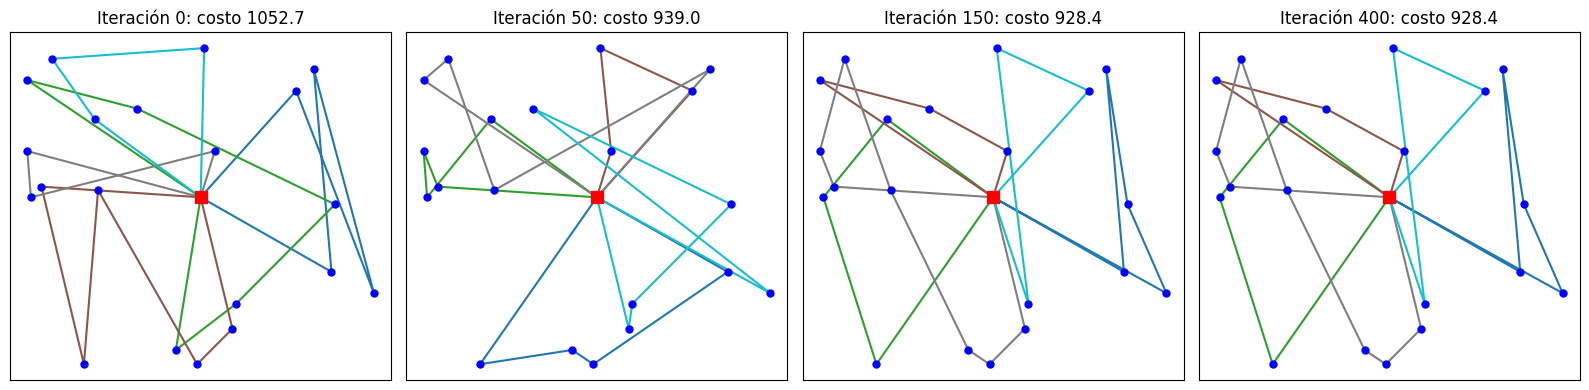

In [21]:
def graficar_rutas_vrp(pso, iteraciones):
    """Dibuja las mejores rutas del enjambre en las iteraciones indicadas"""
    fig, ejes = plt.subplots(1, len(iteraciones), figsize=(4 * len(iteraciones), 4))
    colores = plt.cm.tab10(np.linspace(0, 1, pso.num_vehiculos))
    for ax, k in zip(ejes, iteraciones):
        ax.scatter(pso.deposito[0], pso.deposito[1], c='red', s=80, marker='s', zorder=3)
        ax.scatter([c[0] for c in pso.clientes], [c[1] for c in pso.clientes], c='blue', s=25, zorder=3)
        for i, ruta in enumerate(pso.historial_rutas[k]):
            if not ruta:
                continue
            puntos = [pso.deposito] + [pso.clientes[c][:2] for c in ruta] + [pso.deposito]
            ax.plot([p[0] for p in puntos], [p[1] for p in puntos], c=colores[i], lw=1.5)
        ax.set_title(f'Iteración {k}: costo {pso.historial_fitness[k]:.1f}')
        ax.set_xticks([])
        ax.set_yticks([])
    plt.tight_layout()
    plt.show()

graficar_rutas_vrp(pso, [0, 50, 150, 400])

El costo baja durante las primeras iteraciones y desde la iteración 100 no vuelve a cambiar. Las cargas de las cinco rutas quedan entre 19 y 23 unidades, de modo que la solución no paga penalización, pero las rutas se cruzan y mezclan clientes de zonas alejadas. La explicación está en el decodificador. Como cada cliente va al vehículo con menos carga, clientes consecutivos en el orden de las llaves tienden a quedar en vehículos distintos, sin importar dónde estén. El enjambre cambia el orden de las llaves, pero solo influye de manera indirecta en qué clientes comparten vehículo. Con llaves aleatorias, entonces, las soluciones que la búsqueda puede alcanzar dependen tanto del decodificador como de la regla de movimiento.